In [1]:
import os,json
from pathlib import Path
#import marimo as mo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from utils import boolean_array_to_event_table, bootstrap_cumulative_probability, converting_follow_velocity,bfill,sorting_trial_info, generate_index_points
from plotting_utils import plot_example_trajectory, plot_yaw_angular_velocity, heatmap, annotate_heatmap

from matplotlib.colors import ListedColormap
## a useful function to generate a customised colourmap to repordocue the colour schemes in the Extended Figure 2B (the manuscript in the Zenodo dataset)
custom_5 = ListedColormap(
    ["blue","cyan","red","magenta", "purple"],
    name="custom_5")

# Accessing dataset random dot kinematograms in desert Locusts on Marimo notebook

#### Marimo notebook is similar to jupyter notebook, where you can interact with codes cell by cell (or block by block). Nevertheless, the biggest difference between the two is that Marimo notebook can automatically synchronise the value of global variables to all of the activated cells. This helps demonstrate a database like this, because you do not need to remember which cells to activate and which ones to skip. User feedback is updated automatically. However, jupyter notebook still has better support in other asepects but I found it trickier to prototype a script on Marimo (The promising thing is that Marimo has built up their APIs for users to convert notebooks from juypter notebook to Marimo notebook vice versa).

#### A useful tip for new Marimo notebook users: get used to local variables and global variables

#### What is a local variable on Marimo notebook?
#### A variable whose name starts from an _, for example _file_name
#### When a local variable gets updated, it will only affect code within the same cell. By contrast, a global variable will affect the entire notebook. Therefore, it is impossible to define two global variables with the same name.

## Session 0: loading package depandancies and environmental variables

### Session 0.1: Loading analysis methods into a dictionary variable

In [2]:
# I used python dict to manage how to analyse data. The dictionary is stored in .json file. These commands load json file as a python dictionary
_file_name = './analysis_methods_dictionary.json'
with open(_file_name, 'r') as _f:
    analysis_methods = json.loads(_f.read())

## Session 1: Loading dataset as pandas dataframe

Session 1.1 if you have access to the server of AG Couzin-Fuchs, specify the path to where the database is stored. Otherwises, rewrite the variable **this_dataset_dir** to where you saved the dataset in your computer.

In [3]:
#The raw data following a hierarchical structure where each animal's data is stored in its own folder. Here is an example (LocustID: GN24098).
_folder_name = 'MatrexVR'
#_Datasets = 'Z:/DATA/experiment_trackball_Optomotor'
_Datasets ='/Volumes/AG_Couzin-Fuchs/DATA/experiment_trackball_Optomotor/'
this_dataset_dir = f'{_Datasets}/{_folder_name}'#change here if the dataset is on your computer
animal_ID='GN24098'
experiment_date='240810'
_file_name = 'database_camera2_2024-08-10T17_38_24-20240810_231205.parquet.gzip'

#Once the path of the file is specified, load the data into a pandas dataframe
df = pd.read_parquet(Path(this_dataset_dir) / animal_ID / experiment_date / 'coherence'/ 'session1'/_file_name)

## Session 2: Visualising trajectory of interest

#### Session 2.1 load some variables in the analysis methods dictionary into global variables

In [4]:
camera_fps=analysis_methods.get('camera_fps')
filtering_method=analysis_methods.get("filtering_method")
if np.mod(camera_fps*0.5, 2) == 1:# the default analysis window for smoothing techniques is 0.5 seconds
    smooth_window_length=round(camera_fps*0.5)
else: 
    smooth_window_length=round(camera_fps*0.5)+1 
yaw_axis=analysis_methods.get("yaw_axis","z").lower()

#### Session 2.2 apply smoothing tools to the raw data

In [5]:
if filtering_method == "sg_filter" or filtering_method == "savgol_filter":
    x_all = savgol_filter(df.loc[:, ["intergrated x position"]].values[:,0], smooth_window_length, 3, axis=0)
    y_all = savgol_filter(df.loc[:, ["intergrated y position"]].values[:,0], smooth_window_length, 3, axis=0)
    yaw_angular_velocity = savgol_filter(df.loc[:, [f"delta rotation vector lab {yaw_axis}"]].values[:,0], smooth_window_length, 3, axis=0)

elif filtering_method == "rolling_median":# when applying rolling median to the dataset, NaN value can not be processed. Therefore, we need to apply backward filling methods to fill in those NaN value with the nearest element. The NaN value, if it ever appers, only appears in the beginning of an experiment so it is not going to influence the analysis of trial-related responses
    x_all =df.loc[:, ["intergrated x position"]].rolling(smooth_window_length).median().values
    y_all = df.loc[:, ["intergrated y position"]].rolling(smooth_window_length).median().values
    yaw_angular_velocity =df.loc[:, [f"delta rotation vector lab {yaw_axis}"]].rolling(smooth_window_length).median().values
    x_all=bfill(x_all[:,0])
    y_all=bfill(y_all[:,0])
    yaw_angular_velocity=bfill(yaw_angular_velocity[:,0])
else:
    x_all = df.loc[:, ["intergrated x position"]].values[:,0]
    y_all = df.loc[:, ["intergrated y position"]].values[:,0]
    yaw_angular_velocity = df.loc[:, [f"delta rotation vector lab {yaw_axis}"]].values[:,0] 

####Session 2.3 write in from which frames to which frames you want to visualise the trajectory.

(<Figure size 800x800 with 1 Axes>, <Figure size 1200x700 with 2 Axes>)

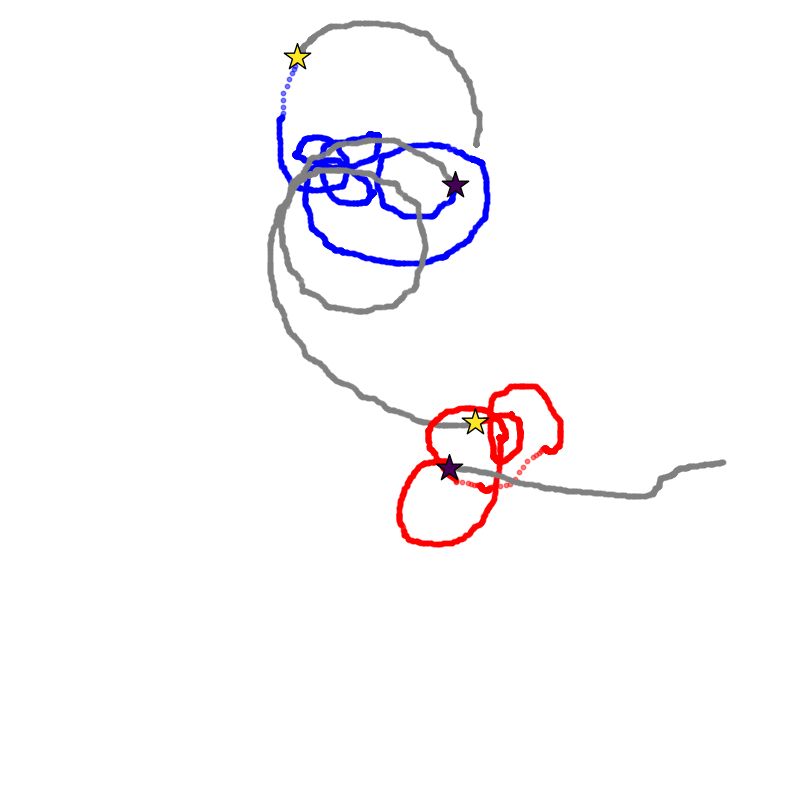

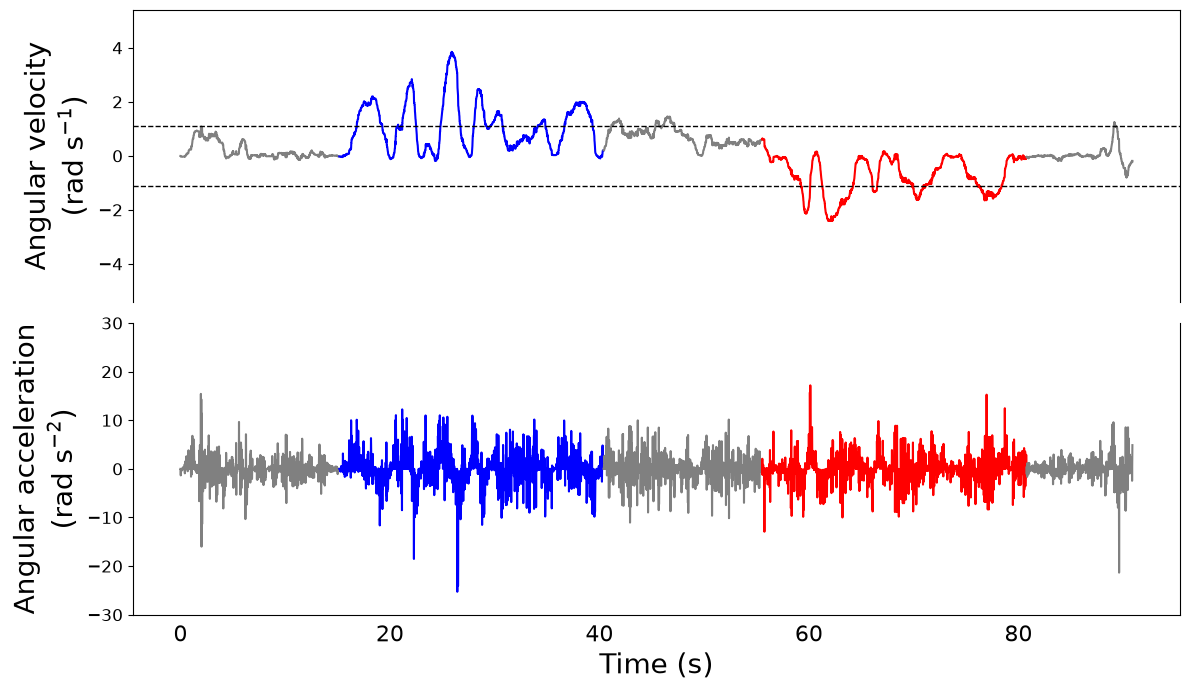

In [6]:
#The first argument after yaw angular veloctiy is start_frame. This is meant to specifiy from which frame you would like to draw the trajectory. end_frame, on the other hand, specifies until which frame to stop drawing the trajectory. start_markers used to denote the start of a trial, whereas the end_marker denotes the end of a trial.

plot_example_trajectory(x_all,y_all,yaw_angular_velocity=yaw_angular_velocity,start_frame=411341,end_frame=420430,start_marker=[412857,416894],end_marker=[415381,419418],analysis_methods=analysis_methods)
#The output here is the figure 1B and 1C in Lee et al., 2026 

## Session 4: studying visually-evoked responses

###Session 4.1: obtain trial information

####Session 4.1.1: load trial information from .csv file

In [7]:
_file_name='trial_events2024-08-10T17_38_17.csv' #specify the file name here
_stim_info = pd.read_csv(Path(this_dataset_dir) / animal_ID / experiment_date / 'coherence'/ 'session1'/_file_name)
stim_info,stim_types=sorting_trial_info(_stim_info, analysis_methods) # call this customised function to parse the csv file into a panda dataframe

In [8]:
#Note: information about inter-stimulus interval is also sved in the rows. This is owing to the design of logging information on the Bonsai workflow, which also treats inter-stimulus intervels as events to log.
print(f"number of trials in this experiment:{stim_info.shape[0]}")

number of trials in this experiment:336


####Session 4.1.2: Use trial information from the curated dataset.

In [9]:
#the trial information is also stored in the curated dataset. As the ID listed up in the curated dataset is different from the ID stored in meta-data and raw dataset, you need to first check the column "Path" to figure out where this animal's trial information is stored in this curated dataset.
_file_name = 'MatrexVR_4coherence_database.parquet.gzip'

##define a new variable for a new path and replace this_data_dir with a new path if the curated dataset and raw dataset are not stored in the same place
curated_dataset_df = pd.read_parquet(Path(this_dataset_dir) / _file_name)

In [10]:
#Here is an example to search for the animal ID of interest in the curated dataset. Note: information about inter-stimulus interval is only saved in columns "isi_onset_thframe", "preStim_ISI_duration", "opto_index_isi" and "travel_distance_isi". There are no dedicated rows for inter-stimulus interval
curated_dataset_df[curated_dataset_df["Path"].str.contains(animal_ID)]['stim_type']

8904   -100
8905      0
8906     33
8907    -33
8908     33
       ... 
9067   -100
9068    -66
9069    100
9070    -33
9071    -66
Name: stim_type, Length: 168, dtype: int64

###Session 4.2: obtain the event timing

####Session 4.2.1: load pixel values from the synchroisation file

In [11]:
_file_name='lux2_2024-08-10T17_38_24.csv' #specify the file name here. Note: this file name was used only within AG Couzin-Fuchs. On Zenodo, it was renamed as 'sync2_2024-08-10T17_38_24.csv'
_sync_file = pd.read_csv(Path(this_dataset_dir) / animal_ID / experiment_date / 'coherence'/ 'session1'/_file_name,delimiter=",", header=0, index_col=None)
led_values=_sync_file.iloc[:, 0].values#The first column is the pixel value and the second column is the timestamp of frames

####Session 4.2.2: select thresholds to define the timing of each transition event (from onset to offset)

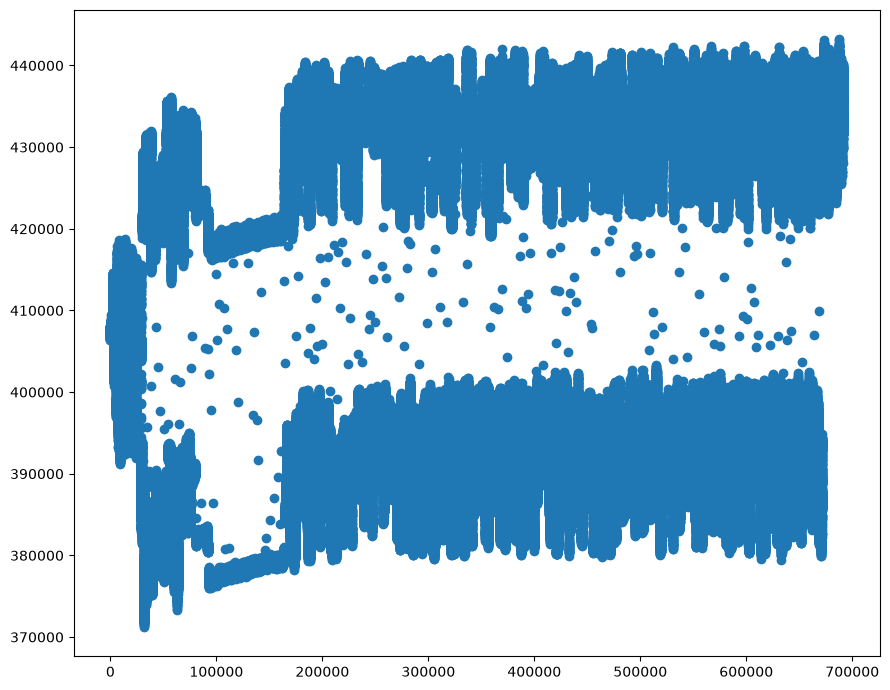

In [12]:
_fig_led, _ax = plt.subplots(nrows=1, ncols=1, figsize=(9, 7), tight_layout=True)
_ax.scatter(np.arange(led_values.shape[0]), led_values)
#here you can plot visualise pixel values of the LED frame by frame and find a threshold.

#### Tips to set a threshold for detecting transition: here you can see the pixel values first fluctuated 390000 and 420000, and then split into two phases, one of them seems to fluctuate between 420000 and 440000; the other one seeems to fluctuate between 380000 and 400000. The frist fluctuation comes from the first 300 second stimulus interval (no-dot grey screen). The two phases come from reading synchorisation patch on the LED panel turning between white (RGB value:1,1,1) and black (RGB value:0,0,0). However, even within one phase, the readouts flucate and stay stable from time to time (for example between frame 100000 and frame 150000 looks much stable than other time points). This is what I meant the signal to noise ratio is low if you directly read the pixel values from a synchronisation path in the Bonsai workflow [Readme](https://github.com/chiyu1203/bonvision_rdk/tree/main/BonsaiWorkflows). The stable line probably came from the time when the animal did not move at all.


#### The good news is that as long as you can see the seperate into two phases after the 5-min grey screen, it is quite possible that you can seperate them

In [13]:
#Since we know how long is the grey screen, we can ignore those readouts based on time and then focus on converting readings from the two phases into transition from the LED on-to-off phase and from the off-to-on phase
pre_stim_grey_screen=analysis_methods.get("prestim_duration")
#Setting an arbitrary threshold to split the two phase
transition_threshold=410000
#to prevent noisy signals from crossing the threshold (false positive detection), we can specify minimal duration for each phase based on how long the inter-stimulus-interval and stimulus presentation were designed in the experiment
_min_stim=analysis_methods.get("stim_duration")
_min_interval=min(analysis_methods.get("interval_duration"))
min_phase_duration=[_min_stim,_min_interval]

In [14]:
_pass_threshold = led_values > transition_threshold
_pass_threshold_index = np.where(_pass_threshold)[0]
#up_phase = np.append(_pass_threshold_index[0],_pass_threshold_index[1:][
#            np.diff(_pass_threshold_index) > min_phase_duration[0] * 0.6 * #camera_fps])
up_phase=_pass_threshold_index[1:][np.diff(_pass_threshold_index) > min_phase_duration[0] * 0.6 * camera_fps]
b2w = up_phase[up_phase > camera_fps * pre_stim_grey_screen]

_pass_threshold = transition_threshold > led_values
_pass_threshold_index = np.where(_pass_threshold)[0]
down_phase = _pass_threshold_index[1:][np.diff(_pass_threshold_index) > min_phase_duration[1] * 0.6 *camera_fps]
w2b = down_phase[down_phase > camera_fps * pre_stim_grey_screen]# remove transition during pre-stim grey screen
#Here you will notice that there is one more event logged for b2w than for w2b. That event came from an additional transition during which the last stimulus was delivered (the screen switch bacn to grey screen)

In [15]:
_num_stimulus=int(stim_info.shape[0]/2)
stim_to_analyse=w2b[:_num_stimulus]+1# When the transition happens on the Nth frame, you can say the stimulus also starts from Nth frame, but I would prefer to define it as N+1th frame. Note: when temporal accuracy is required, you would probably needs to set two thresholds for detecting transitions. One of them closer to the LED on phase and the other one closer to the LED off phase. In this design, you can capture the exact time when the value starts to cross thresholds (of leaving a phase and of entering another phase).

###Session 4.3: align data with event timing.

####Session 4.3.1: Use the timing of events from 4.1 session

In [16]:
analysis_window=analysis_methods.get('analysis_window')
_index_points=generate_index_points(stim_to_analyse,analysis_window,camera_fps)
angular_velocity_tbt=yaw_angular_velocity[_index_points]

####Session 4.3.2: Use event timing from the curated database

In [17]:
#Similar to Session 4.1.2, you can directly extract that information from the curated dataset.
curated_dataset_df[curated_dataset_df["Path"].str.contains(animal_ID)]['stim_onset_thframe']

8904     31196
8905     34730
8906     38770
8907     42808
8908     46846
         ...  
9067    653664
9068    657200
9069    661237
9070    665277
9071    668810
Name: stim_onset_thframe, Length: 168, dtype: int64

### Session 4.4: Visualise invidual animal's responses across trials

In [18]:
#This step is not necessary but I found it easier to sort data out in pandas dataframe first
_tmp=pd.DataFrame(angular_velocity_tbt)
_stim_info_trial_only=stim_info[1::2].reset_index(drop=True, inplace=False)
df_angular_velocity=pd.concat((_stim_info_trial_only, _tmp), axis=1)

/var/folders/50/spzyp8t97pz1dlqqjnmhl3_r0000gn/T/ipykernel_56956/1398223149.py:3: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  _stim_info_trial_only=stim_info[1::2].reset_index(drop=True, inplace=False)


#### Session 4.4.1: Use angular_velocity trial by trial and stim_info to plot median angular velocity

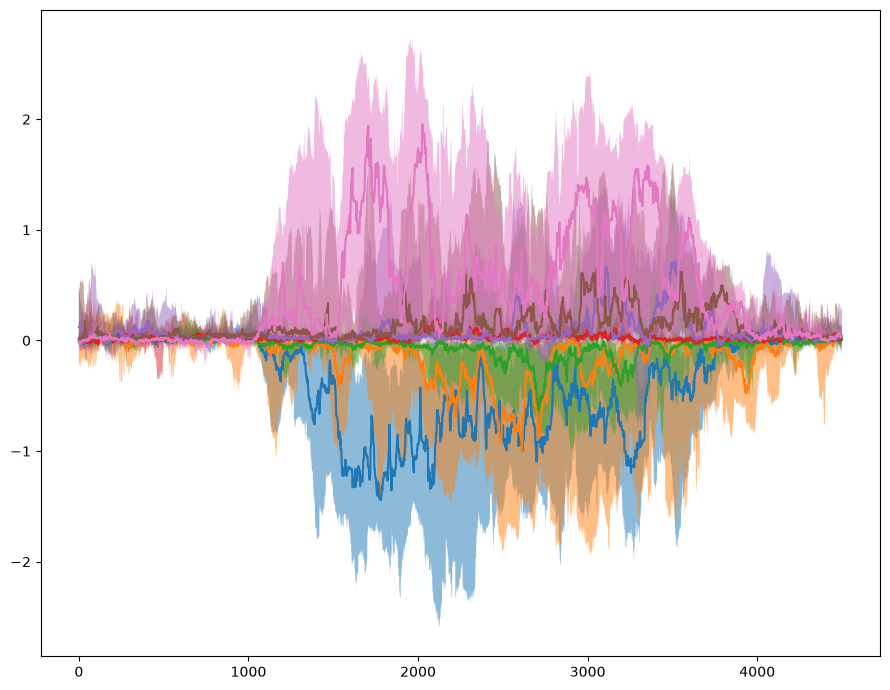

In [19]:
_fig_angular_velocity, _ax = plt.subplots(nrows=1, ncols=1, figsize=(9, 7), tight_layout=True)
_time_points = np.arange(angular_velocity_tbt.shape[1])
for _this_stim, _entries in df_angular_velocity.groupby('stim_type'):
    _angular_velocity=_entries.iloc[:,11:]
    _w_to_plot=velocity_to_plot=np.median(_angular_velocity, axis=0)
    _res=st.bootstrap(data=(_angular_velocity,),statistic=np.median,n_resamples=99,vectorized=True,batch=100,random_state=1)
    _w_y1=_res.confidence_interval[0]
    _w_y2=_res.confidence_interval[1]
    _ax.plot(_time_points,_w_to_plot)
    _ax.fill_between(_time_points,_w_y1,_w_y2, alpha=0.5)

#### Session 4.4.2: reuse the customised function from plotting_utils to reproduce the Figure 1E in Lee et al., 2026

/Users/chiyu_lee/Documents/GitHub/bonvision_rdk/Analysis/.venv/lib/python3.14/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/chiyu_lee/Documents/GitHub/bonvision_rdk/Analysis/.venv/lib/python3.14/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)
/Users/chiyu_lee/Documents/GitHub/bonvision_rdk/Analysis/.venv/lib/python3.14/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/chiyu_lee/Documents/GitHub/bonvision_rdk/Analysis/.venv/lib/python3.14/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution 

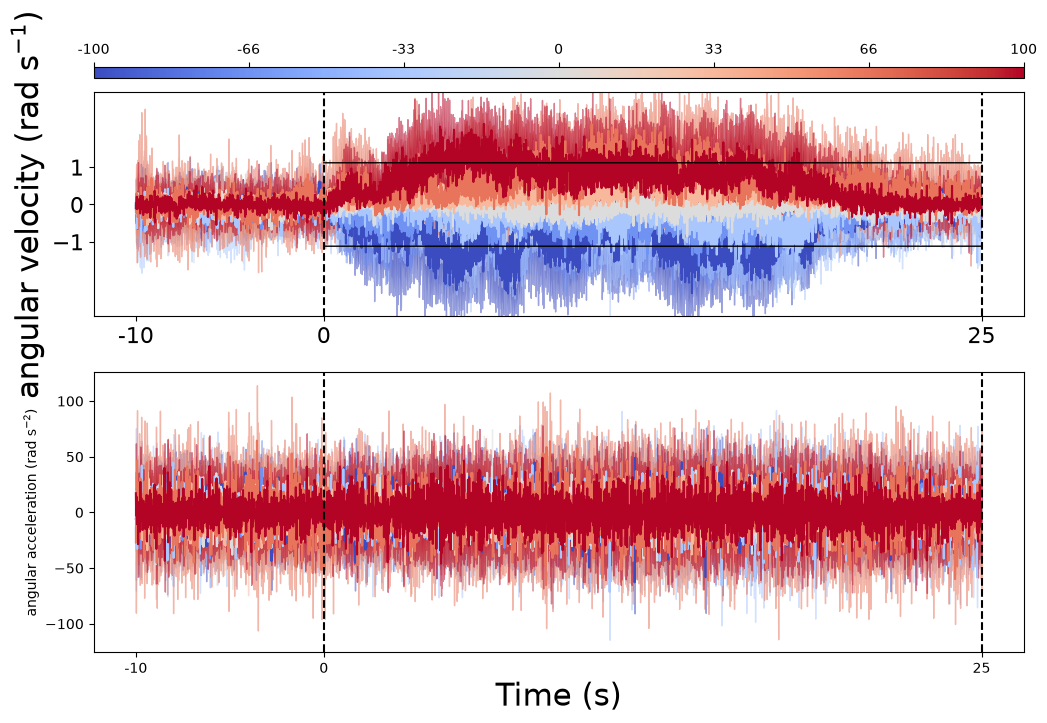

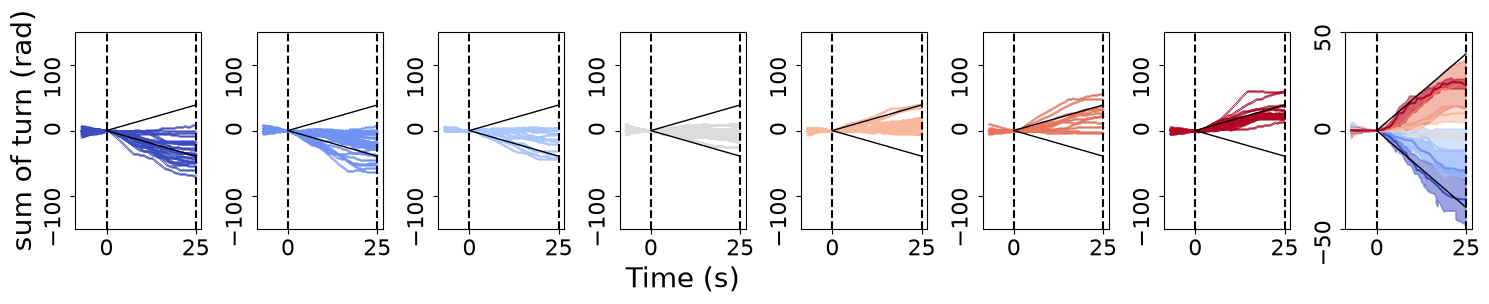

In [20]:
#to visualise this animal's response without building up a new dataframe, you can simply load angular veloctiy from the curated dataset, with this command: curated_dataset_df[curated_dataset_df["Path"].str.contains(animal_ID)]
init_frame=abs(analysis_window[0])*camera_fps
end_frame=(abs(analysis_window[0])+analysis_window[1])*camera_fps
_fig,_fig_tbt=plot_yaw_angular_velocity(curated_dataset_df[curated_dataset_df["Path"].str.contains(animal_ID)],analysis_methods,init_frame=init_frame,end_frame=end_frame,vr_no="single")

##Session 5: Other metrics to study

### Session 5.1: calculating animal's speed

#### We can calculate the animal's speed by getting how far they move every frame (in euclidean distance) and then divided the time difference between each frame (or multipled by the camera acqusition rate)

In [21]:
def euclidean_distance(X,Y):
    return np.sqrt(np.add(np.square(np.diff(X)), np.square(np.diff(Y))))

In [22]:
_travel_distance_fbf = euclidean_distance(x_all,y_all)
speed=_travel_distance_fbf*camera_fps
print(speed)

[0.         0.         0.         ... 7.04797673 5.24816646 2.28762695]


### Session 5.2: calculating optomotor index

#### Here, we can define an index to quantify optomotor walking behaviour as the net angular velocities (clockwises and clockwise) for a given trial, normalised by the sum of the absolute value of the angular velocities. This index gives you an easy way to check how well the animal respond to rotational cues (at the cost of losing details of the turning behaviour because all the data is compressed into a single value).
For details, please refer to [Sayin et al. 2025](https://www.science.org/doi/10.1126/science.adq7832), and [Seelig et al., 2010](https://www.nature.com/articles/nmeth.1468).

In [23]:
def optomotor_response_idx(ev_dat):
    opt_idx = (
        np.nansum(abs(ev_dat[ev_dat > 0])) - np.nansum(abs(ev_dat[ev_dat < 0]))
    ) / (np.nansum(abs(ev_dat[ev_dat < 0])) + np.nansum(abs(ev_dat[ev_dat > 0])))
    return opt_idx

In [24]:
#calculate optomotor index: You need to specify from which frame to which frame and at trial to calculate the optomotor index. The example here shows you the calculation of optomotor index at the first trial, from the start of the stimulation presentation until the end of the stimulus presentation 
opt_idx=optomotor_response_idx(angular_velocity_tbt[0,init_frame:end_frame])
print(opt_idx)

0.3836865989407563
